# KNN Benchmark — Interactive Analysis

This notebook is the **analysis surface** for the KNN sweet-spot benchmark.

It reuses the extraction logic from `analyze_benchmark.py` (the reproducible *engine*) so
there is a single source of truth for how metrics are pulled from each experiment. The
engine crawls every `results/exp_*` folder once; here we explore the resulting tidy table
interactively, make the paper's figures, and do the descriptive analysis / interpretation.

**Workflow:** `results/exp_*/`  →  `build_summary()`  →  tidy `summary` DataFrame  →  plots & stats.

In [37]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

# Make the extraction engine importable (it lives next to this notebook)
NB_DIR = Path.cwd()
if str(NB_DIR) not in sys.path:
    sys.path.insert(0, str(NB_DIR))
import analyze_benchmark as ab

RESULTS_DIR = (NB_DIR.parent / 'results').resolve()
print('Results dir:', RESULTS_DIR)
print('Engine functions:', [f for f in dir(ab) if not f.startswith('__')][:12], '...')

Results dir: C:\Users\jonas\DBE\KNN Sampling\tinymlops-framework\server\benchmark\results
Engine functions: ['CLASS_LABELS', 'Dict', 'HAVE_SCIPY', 'List', 'METRICS', 'Optional', 'Path', '_ci95', '_latest', '_plot_metric_vs_samples', '_read_power_csv', '_table'] ...


## 1. Load the tidy data (Level 1)

One row per completed experiment. This is recomputed live from the result folders, so it is
always in sync with whatever has finished running. (Equivalent to `experiment_summary.csv`.)

In [38]:
summary = ab.build_summary(RESULTS_DIR)
print(f'{len(summary)} experiments loaded')
summary

240 experiments loaded


,experiment_id,pca_enabled,pca_components,pca_label,samples_per_class,seed,pca_explained_variance_pct,n_images,accuracy,latency_ms_mean,...,cpu_percent_mean,memory_rss_mb_mean,memory_rss_mb_max,knn_store_kb,drift_events,avg_power_W,net_avg_power_W,energy_per_image_J,net_energy_per_image_J,inference_duration_s
0,exp_121_nopca_spc2_s42,False,NaN,nopca,2,42,NaN,200,0.510,45.445331,...,5.047739,59.796500,59.85,NaN,0,0.7813,0.1673,0.190990,0.040898,48.892
1,exp_122_nopca_spc2_s123,False,NaN,nopca,2,123,NaN,200,0.560,45.286088,...,5.071357,59.699600,59.76,NaN,0,0.7957,0.1817,0.194902,0.044505,48.987
2,exp_123_nopca_spc2_s456,False,NaN,nopca,2,456,NaN,200,0.415,45.489122,...,5.065327,59.739250,59.80,NaN,0,0.8000,0.1860,0.195575,0.045470,48.892
3,exp_124_nopca_spc2_s789,False,NaN,nopca,2,789,NaN,200,0.525,47.123700,...,5.206061,59.701960,59.76,NaN,0,0.7833,0.1693,0.191126,0.041310,48.801
4,exp_125_nopca_spc2_s1337,False,NaN,nopca,2,1337,NaN,200,0.505,46.630822,...,5.122727,59.677487,59.74,NaN,0,0.7807,0.1667,0.190346,0.040646,48.765
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235,exp_119_pca31_spc100_s1618,True,31.0,pca31,100,1618,95.141106,200,0.780,47.039835,...,5.157360,60.721566,60.78,121.09375,0,0.7969,0.1829,0.195587,0.044887,49.084
236,exp_116_pca31_spc100_s2021,True,31.0,pca31,100,2021,95.141106,200,0.785,47.290472,...,5.202577,60.655641,60.71,121.09375,0,0.7985,0.1845,0.195017,0.045058,48.843
237,exp_118_pca31_spc100_s2718,True,31.0,pca31,100,2718,95.141106,200,0.780,47.839147,...,5.221106,60.774900,60.83,121.09375,0,0.8041,0.1901,0.201253,0.047577,50.055
238,exp_117_pca31_spc100_s3141,True,31.0,pca31,100,3141,95.141106,200,0.840,47.751900,...,5.219095,60.595500,60.65,121.09375,0,0.7927,0.1787,0.198134,0.044666,49.990


## 2. Aggregate across seeds (Level 2)

Each `(pca, samples_per_class)` cell is averaged over its seeds (the replicates). We report
**mean**, **std**, and the **95% confidence interval of the mean** (t-based). This is the
table the paper's curves plot.

In [39]:
agg = ab.aggregate(summary)
agg

,pca_label,pca_enabled,samples_per_class,n_seeds,accuracy_mean,accuracy_std,accuracy_ci95,net_energy_per_image_J_mean,net_energy_per_image_J_std,net_energy_per_image_J_ci95,...,avg_power_W_ci95,cpu_percent_mean_mean,cpu_percent_mean_std,cpu_percent_mean_ci95,memory_rss_mb_mean_mean,memory_rss_mb_mean_std,memory_rss_mb_mean_ci95,latency_ms_mean_mean,latency_ms_mean_std,latency_ms_mean_ci95
0,nopca,False,2,10,0.5335,0.051857,0.037096,0.041953,0.002224,0.001591,...,0.006333,5.123040,0.079559,0.056913,59.723064,0.037306,0.026687,46.166940,0.805146,0.575967
1,nopca,False,5,10,0.7075,0.026693,0.019095,0.042200,0.002916,0.002086,...,0.008588,5.118924,0.054073,0.038681,59.829913,0.066287,0.047419,45.916426,0.479545,0.343046
2,nopca,False,10,10,0.7475,0.028504,0.020391,0.040510,0.001114,0.000797,...,0.003760,5.116559,0.046008,0.032912,59.944779,0.046476,0.033247,46.182267,0.707690,0.506251
3,nopca,False,20,10,0.7580,0.018288,0.013082,0.041949,0.003098,0.002216,...,0.008404,5.216130,0.140140,0.100250,60.311960,0.033209,0.023756,46.734360,0.581807,0.416200
4,nopca,False,30,10,0.7690,0.023070,0.016503,0.041509,0.002062,0.001475,...,0.006202,5.252118,0.221289,0.158301,60.764345,0.087125,0.062325,46.998460,0.728958,0.521465
5,nopca,False,40,10,0.7770,0.017981,0.012863,0.041995,0.001046,0.000748,...,0.003472,5.189335,0.075974,0.054349,60.927104,0.367294,0.262747,47.501453,0.866037,0.619526
6,nopca,False,50,10,0.7785,0.029064,0.020791,0.042682,0.002049,0.001575,...,0.007056,5.264823,0.156121,0.111682,60.994518,0.606189,0.433641,47.443412,0.819468,0.586212
7,nopca,False,60,10,0.7830,0.020440,0.014622,0.046080,0.001447,0.001035,...,0.003394,5.257018,0.149303,0.106805,61.554207,0.569280,0.407238,47.658426,0.577321,0.412991
8,nopca,False,70,10,0.7785,0.020007,0.014312,0.046313,0.002286,0.001636,...,0.006760,5.291509,0.183184,0.131042,62.096779,0.504439,0.360854,48.064647,0.483291,0.345726
9,nopca,False,80,10,0.7800,0.028868,0.020651,0.047954,0.002117,0.001515,...,0.006338,5.256583,0.066549,0.047606,62.214856,0.618139,0.442190,48.114835,0.662227,0.473728


## 3. The paper's curves — metric vs reference samples per class

Accuracy / Energy / Memory / CPU vs samples-per-class, one line per pipeline (PCA vs no-PCA),
with shaded 95% CI bands. Tweak `metrics_to_plot` to explore others
(`avg_power_W`, `latency_ms_mean`, ...).

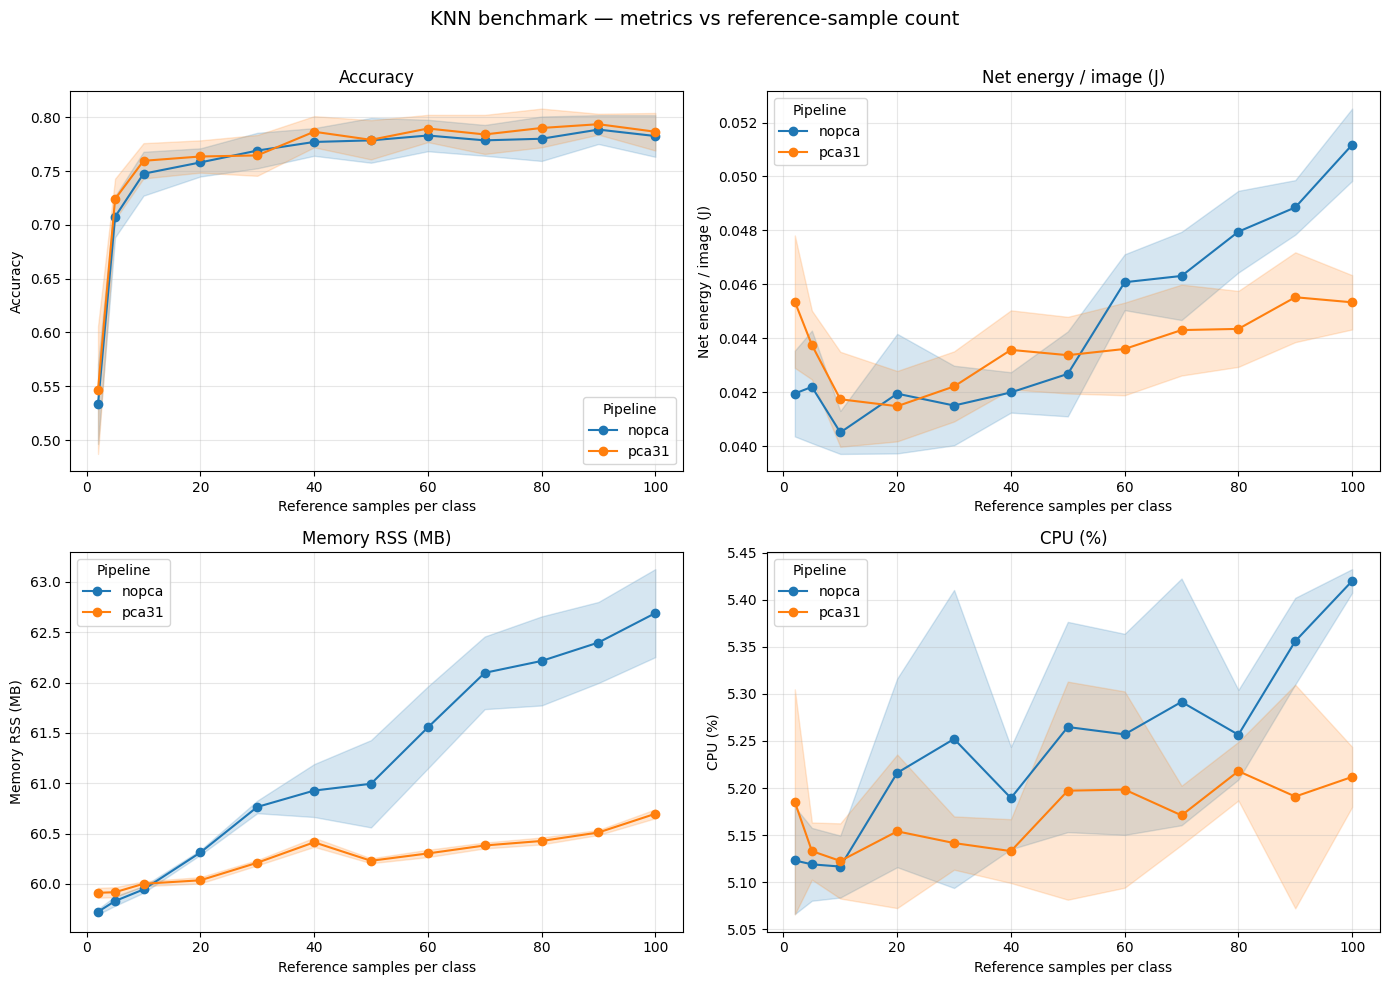

In [40]:
metrics_to_plot = [
    ('accuracy', 'Accuracy'),
    ('net_energy_per_image_J', 'Net energy / image (J)'),
    ('memory_rss_mb_mean', 'Memory RSS (MB)'),
    ('cpu_percent_mean', 'CPU (%)'),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (metric, title) in zip(axes.ravel(), metrics_to_plot):
    for pca_label, sub in agg.groupby('pca_label'):
        sub = sub.sort_values('samples_per_class')
        x = sub['samples_per_class'].to_numpy()
        y = sub[f'{metric}_mean'].to_numpy()
        ci = np.nan_to_num(sub[f'{metric}_ci95'].to_numpy(), nan=0.0)
        if np.all(np.isnan(y)):
            continue
        line, = ax.plot(x, y, marker='o', label=pca_label)
        ax.fill_between(x, y - ci, y + ci, alpha=0.18, color=line.get_color())
    ax.set_title(title); ax.set_xlabel('Reference samples per class'); ax.set_ylabel(title)
    ax.grid(alpha=0.3); ax.legend(title='Pipeline')
fig.suptitle('KNN benchmark — metrics vs reference-sample count', fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

## 4. Sweet spot & PCA effect

- **Sweet spot:** smallest sample count reaching 99% of the max mean accuracy (the knee).
- **PCA effect:** paired comparison (PCA vs no-PCA) at matched (samples, seed), Wilcoxon test.

In [41]:
import json
print('Sweet spot:'); print(json.dumps(ab.find_sweet_spot(agg), indent=2))
print('\nPCA effect (paired):'); print(json.dumps(ab.pca_effect(summary), indent=2))

Sweet spot:
{
  "nopca": {
    "max_accuracy": 0.7885000000000001,
    "target_accuracy": 0.7806150000000001,
    "sweet_spot_samples_per_class": 60
  },
  "pca31": {
    "max_accuracy": 0.7935000000000001,
    "target_accuracy": 0.7855650000000001,
    "sweet_spot_samples_per_class": 40
  }
}

PCA effect (paired):
{
  "accuracy": {
    "pca_label": "pca31",
    "nopca_label": "nopca",
    "n_pairs": 120,
    "mean_pca": 0.7555833333333333,
    "mean_nopca": 0.7486250000000001,
    "mean_diff_pca_minus_nopca": 0.006958333333333335,
    "wilcoxon_p": 0.00011798616671677102
  },
  "net_energy_per_image_J": {
    "pca_label": "pca31",
    "nopca_label": "nopca",
    "n_pairs": 118,
    "mean_pca": 0.0437197966101695,
    "mean_nopca": 0.04445248305084746,
    "mean_diff_pca_minus_nopca": -0.0007326864406779657,
    "wilcoxon_p": 0.09042200816697792
  }
}


## 5. Seed variability

How much does the random reference-sample / test-order draw move accuracy? Wide spread at
small sample counts is expected; it should shrink as samples grow. This justifies repeating
over seeds rather than trusting a single run.

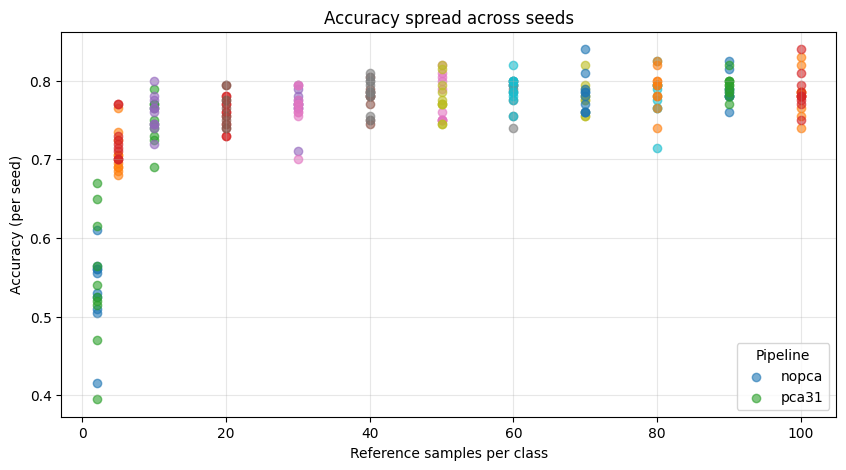

In [42]:
fig, ax = plt.subplots(figsize=(10, 5))
for pca_label, sub in summary.groupby('pca_label'):
    for spc, g in sub.groupby('samples_per_class'):
        ax.scatter([spc] * len(g), g['accuracy'], alpha=0.6,
                   label=pca_label if spc == sub['samples_per_class'].min() else None)
ax.set_xlabel('Reference samples per class'); ax.set_ylabel('Accuracy (per seed)')
ax.set_title('Accuracy spread across seeds'); ax.grid(alpha=0.3); ax.legend(title='Pipeline')
plt.show()

## 6. Per-experiment deep dive

Pick one experiment to inspect its inference timeline and confusion matrix. Set `EXP_ID` to
any value from `summary['experiment_id']`.

exp_120_pca31_spc100_s9876 | 200 inferences | final acc: 0.775


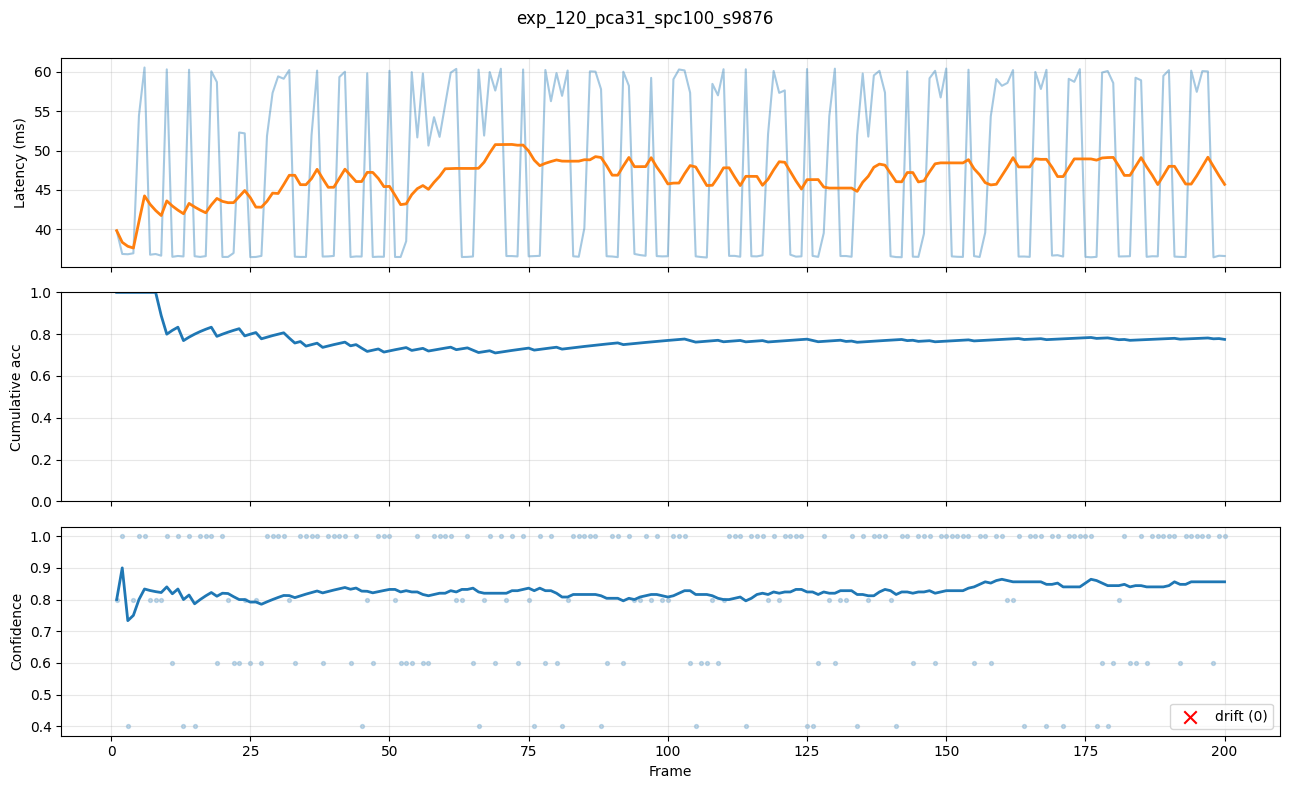

In [43]:
EXP_ID = summary['experiment_id'].iloc[-1]   # <-- change me
exp_dir = RESULTS_DIR / EXP_ID
merged_path = next(iter(sorted(exp_dir.glob('merged_analysis_*.csv'))))
df = pd.read_csv(merged_path)
print(EXP_ID, '|', len(df), 'inferences | final acc:', df['final_accuracy'].dropna().iloc[-1])

fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
axes[0].plot(df['frame_count'], df['latency_ms'], alpha=0.4)
axes[0].plot(df['frame_count'], df['latency_ms'].rolling(20, min_periods=1).mean(), lw=2)
axes[0].set_ylabel('Latency (ms)'); axes[0].grid(alpha=0.3)
axes[1].plot(df['frame_count'], df['cumulative_accuracy'], lw=2)
axes[1].set_ylabel('Cumulative acc'); axes[1].set_ylim(0, 1); axes[1].grid(alpha=0.3)
axes[2].scatter(df['frame_count'], df['confidence'], s=8, alpha=0.25)
axes[2].plot(df['frame_count'], df['confidence'].rolling(50, min_periods=1).mean(), lw=2)
drift = df[ab._to_bool(df['drift_detected'])]
axes[2].scatter(drift['frame_count'], drift['confidence'], marker='x', s=80,
                color='red', label=f'drift ({len(drift)})')
axes[2].set_ylabel('Confidence'); axes[2].set_xlabel('Frame'); axes[2].grid(alpha=0.3); axes[2].legend()
fig.suptitle(EXP_ID); fig.tight_layout(rect=[0, 0, 1, 0.98]); plt.show()

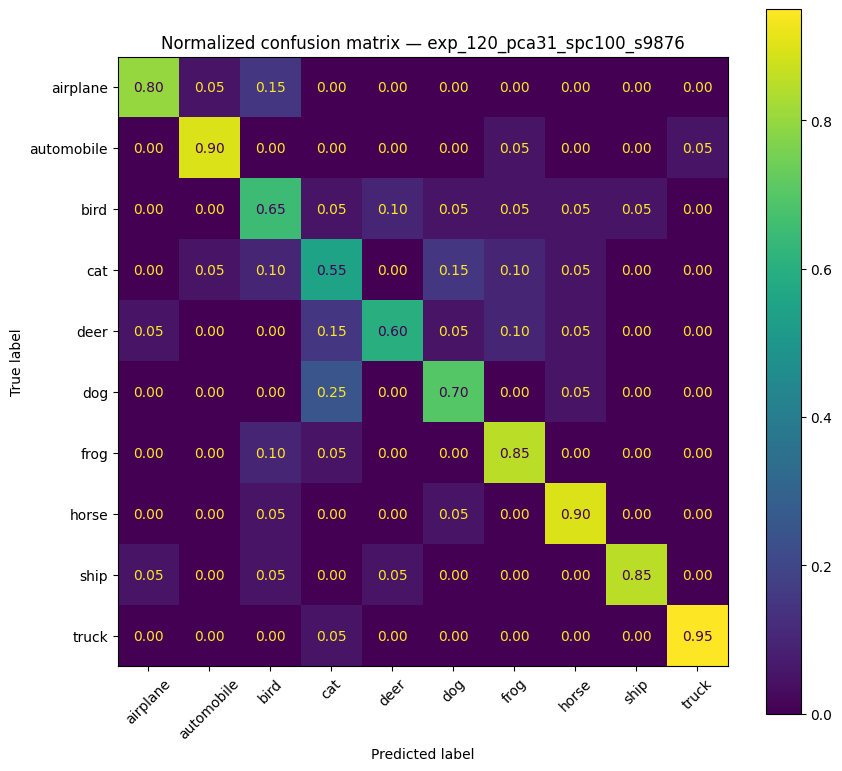

In [44]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

labels = ab.CLASS_LABELS
cm = confusion_matrix(df['ground_truth'], df['prediction'], labels=labels, normalize='true')
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, values_format='.2f', xticks_rotation=45)
ax.set_title(f'Normalized confusion matrix — {EXP_ID}')
plt.tight_layout(); plt.show()

## 7. Power trace for one experiment

Raw Voltcraft readings over time, aligned to the inference window. The flat low region before
`t=0` (if visible) is deployment/boot; the active region is inference.

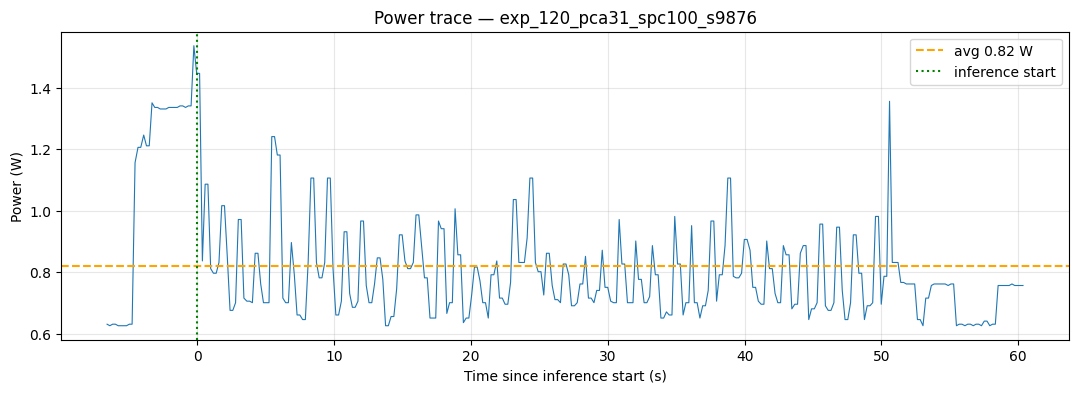

In [45]:
power_path = next(iter(sorted(exp_dir.glob('power_*.csv'))), None)
if power_path is None:
    print('No power CSV for', EXP_ID)
else:
    # Use the engine's parser: it converts the naive local ISO timestamps to true
    # epoch seconds via datetime.timestamp() (tz-aware, resolution-safe). Avoid
    # pd.to_datetime().astype('int64'), which mis-scales naive local timestamps.
    ts_p, pw = (np.asarray(a, dtype=float) for a in ab._read_power_csv(power_path))
    t0 = pd.to_numeric(df['timestamp_unix'], errors='coerce').min()
    t_rel = ts_p - t0
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(t_rel, pw, lw=0.8)
    ax.axhline(pw.mean(), ls='--', color='orange', label=f'avg {pw.mean():.2f} W')
    ax.axvline(0, ls=':', color='green', label='inference start')
    ax.set_xlabel('Time since inference start (s)'); ax.set_ylabel('Power (W)')
    ax.set_title(f'Power trace — {EXP_ID}'); ax.grid(alpha=0.3); ax.legend(); plt.show()

## 8. Memory cost of stored samples & PCA explained variance

Two things the RSS plot in §3 can't show:

- **KNN store size** — the *deterministic* memory the reference set occupies:
  `samples_per_class × n_classes × feature_dim × 4 bytes` (float32). This is the part that
  actually grows as samples are added (RSS is dominated by the ~60 MB Python+TFLite runtime).
  PCA shrinks `feature_dim` (160 → n_components), so its per-sample cost is far smaller.
- **PCA explained variance** — how much of the original 160-D feature variance each PCA
  configuration keeps. Justifies the dimensionality reduction (paper §1.6.4 d).

Raw feature dim (no-PCA stored vector length): 160


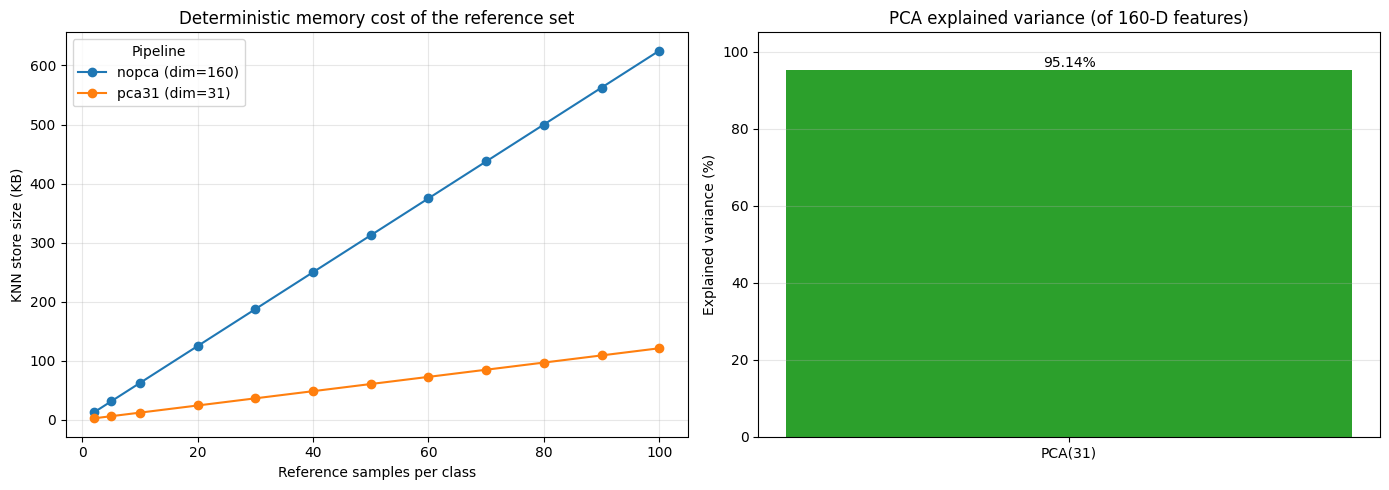

In [46]:
# Feature dim per pipeline: PCA keeps n_components; no-PCA stores the raw extractor output.
# Discover the raw dim from the feature_processor .npz (input_dim); fall back to 160 (CIFAR-10).
RAW_FEATURE_DIM = None
for cand in NB_DIR.parents[2].glob('server/**/scenario_cifar10_knn_benchmark/model/feature_processor*.npz'):
    try:
        RAW_FEATURE_DIM = int(np.load(cand, allow_pickle=True)['input_dim']); break
    except Exception:
        continue
if RAW_FEATURE_DIM is None:
    RAW_FEATURE_DIM = 160
print('Raw feature dim (no-PCA stored vector length):', RAW_FEATURE_DIM)

N_CLASSES = len(ab.CLASS_LABELS)
dims = {}                                            # feature_dim per pipeline label
for lbl, sub in summary.groupby('pca_label'):
    pc = sub['pca_components'].dropna()
    dims[lbl] = int(pc.iloc[0]) if len(pc) else RAW_FEATURE_DIM

def store_kb(spc, dim):
    return spc * N_CLASSES * dim * 4 / 1024.0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# (left) deterministic KNN reference-store size vs samples-per-class, per pipeline
spc_vals = np.array(sorted(summary['samples_per_class'].dropna().unique()))
for lbl in sorted(dims):
    ax1.plot(spc_vals, [store_kb(s, dims[lbl]) for s in spc_vals],
             marker='o', label=f'{lbl} (dim={dims[lbl]})')
ax1.set_xlabel('Reference samples per class'); ax1.set_ylabel('KNN store size (KB)')
ax1.set_title('Deterministic memory cost of the reference set')
ax1.grid(alpha=0.3); ax1.legend(title='Pipeline')

# (right) PCA explained variance per PCA configuration
pca_rows = summary[summary['pca_enabled'] == True].dropna(subset=['pca_explained_variance_pct'])
if not pca_rows.empty:
    ev = pca_rows.groupby('pca_components')['pca_explained_variance_pct'].mean()
    bars = ax2.bar([f'PCA({int(c)})' for c in ev.index], ev.values, color='tab:green')
    for b, v in zip(bars, ev.values):
        ax2.text(b.get_x() + b.get_width() / 2, v, f'{v:.2f}%', ha='center', va='bottom')
    ax2.set_ylim(0, 105)
else:
    ax2.text(0.5, 0.5, 'No PCA runs', ha='center', va='center')
ax2.set_ylabel('Explained variance (%)')
ax2.set_title('PCA explained variance (of 160-D features)'); ax2.grid(alpha=0.3, axis='y')
fig.tight_layout(); plt.show()

## 9. Energy in battery terms — charge per inference (mAh)

Energy in Joules is the physically correct measure, but for a rover on a small battery it is
easier to reason in **charge (mAh)** against the pack's rating. The DSP-3005 ran the Pi at a
near-constant **~5.01 V** (min/mean/max 5.009 / 5.010 / 5.010 across a trace), so charge
converts cleanly from energy:

$$Q\,[\text{mAh}] = \frac{E\,[\text{J}]}{V \times 3.6}, \qquad 1\,\text{mAh} = 3.6\,\text{C} = V \times 3.6\ \text{J}$$

We report the **net** (idle-subtracted) charge — the marginal cost of one inference — and how
many inferences a hypothetical `BATTERY_MAH` pack would sustain on that marginal draw alone.
Caveat: mAh is only meaningful **at a stated voltage**; these figures are at the 5 V supply rail
(a 300 mAh cell at a *different* nominal voltage stores different energy).

Battery reference @ 5.0 V, 300 mAh pack  (1 mAh = 18.0 J):


,pipeline,net uAh/img,gross uAh/img,inferences/300mAh (net),inferences/300mAh (gross)
0,nopca,2.469,10.875,121496,27585
1,pca31,2.429,10.787,123510,27812


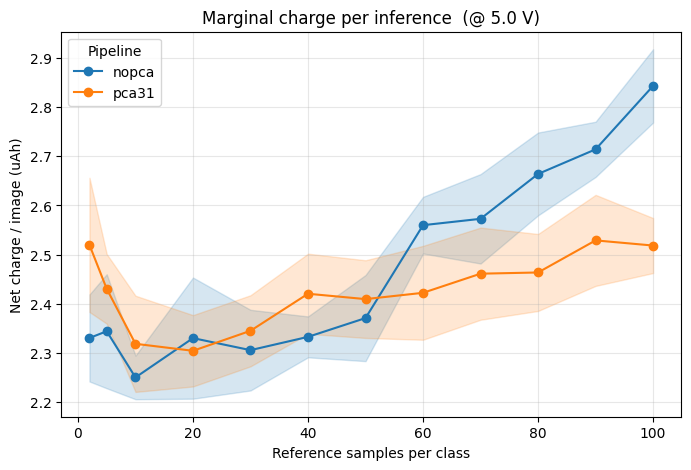

In [47]:
SUPPLY_V    = 5.0     # supply rail the Pi runs on (DSP measured ~5.01 V, stable)
BATTERY_MAH = 300.0   # rover battery capacity to reference against   <-- edit me

J_PER_MAH = SUPPLY_V * 3.6          # energy stored in 1 mAh at the supply voltage (= 18 J)

# Per-experiment charge columns (uAh = micro-amp-hours; per-image draw is tiny)
summary['charge_per_image_uAh']     = summary['energy_per_image_J']     / J_PER_MAH * 1000
summary['net_charge_per_image_uAh'] = summary['net_energy_per_image_J'] / J_PER_MAH * 1000

# Mirror onto the aggregated table (charge is a linear scale of the energy aggregates)
for suf in ('mean', 'std', 'ci95'):
    col = f'net_energy_per_image_J_{suf}'
    if col in agg.columns:
        agg[f'net_charge_per_image_uAh_{suf}'] = agg[col] / J_PER_MAH * 1000

# Battery-reference table per pipeline (mean over all sample counts & seeds)
rows = []
for lbl, sub in summary.groupby('pca_label'):
    net_uAh   = sub['net_charge_per_image_uAh'].mean()
    gross_uAh = sub['charge_per_image_uAh'].mean()
    rows.append({
        'pipeline': lbl,
        'net uAh/img': round(net_uAh, 3),
        'gross uAh/img': round(gross_uAh, 3),
        f'inferences/{int(BATTERY_MAH)}mAh (net)':   int(BATTERY_MAH * 1000 / net_uAh),
        f'inferences/{int(BATTERY_MAH)}mAh (gross)': int(BATTERY_MAH * 1000 / gross_uAh),
    })
battery_tbl = pd.DataFrame(rows)
print(f'Battery reference @ {SUPPLY_V} V, {BATTERY_MAH:.0f} mAh pack  (1 mAh = {J_PER_MAH:.1f} J):')
display(battery_tbl)

# Net charge per image vs samples (battery-flavoured twin of the energy curve)
fig, ax = plt.subplots(figsize=(8, 5))
for lbl, sub in agg.groupby('pca_label'):
    sub = sub.sort_values('samples_per_class')
    y = sub.get('net_charge_per_image_uAh_mean')
    if y is None or np.all(np.isnan(y.to_numpy())):
        continue
    ci = np.nan_to_num(
        sub.get('net_charge_per_image_uAh_ci95', pd.Series(0.0, index=sub.index)).to_numpy(),
        nan=0.0)
    line, = ax.plot(sub['samples_per_class'], y, marker='o', label=lbl)
    ax.fill_between(sub['samples_per_class'], y - ci, y + ci, alpha=0.18, color=line.get_color())
ax.set_xlabel('Reference samples per class'); ax.set_ylabel('Net charge / image (uAh)')
ax.set_title(f'Marginal charge per inference  (@ {SUPPLY_V} V)')
ax.grid(alpha=0.3); ax.legend(title='Pipeline'); plt.show()

## 10. Export results — model-tagged for SVM / K-means comparison

The benchmark currently covers **one classifier (KNN)** in several PCA configs. The paper also
needs SVM and K-means. To make that drop-in later, we export the tidy + aggregated tables with
an explicit **`model`** column and a stable schema. When the SVM / K-means runs exist, write
their rows with `model='svm'` / `model='kmeans'` into the same `exports/` folder using the same
columns; `load_all_models()` concatenates them so the curves can be regrouped by `model`
instead of `pca_label`.

In [48]:
MODEL_NAME = 'knn'
EXPORT_DIR = NB_DIR / 'exports'
(EXPORT_DIR / 'figures').mkdir(parents=True, exist_ok=True)

summary_out = summary.copy(); summary_out.insert(0, 'model', MODEL_NAME)
agg_out     = agg.copy();     agg_out.insert(0, 'model', MODEL_NAME)

summary_csv = EXPORT_DIR / f'experiment_summary_{MODEL_NAME}.csv'
agg_csv     = EXPORT_DIR / f'aggregated_by_config_{MODEL_NAME}.csv'
summary_out.to_csv(summary_csv, index=False)
agg_out.to_csv(agg_csv, index=False)

# Standard paper figures (reuses the engine so the notebook & headless run match)
ab.plot_paper_curves(agg, EXPORT_DIR / 'figures')
ab.plot_pca_variance(summary, EXPORT_DIR / 'figures')

print('Wrote:')
for p in (summary_csv, agg_csv):
    print('  ', p.relative_to(NB_DIR), f'({p.stat().st_size/1024:.1f} KB)')
print('  ', (EXPORT_DIR / 'figures').relative_to(NB_DIR), '/*.png')

def load_all_models(export_dir: Path = EXPORT_DIR) -> pd.DataFrame:
    """Concatenate every exports/experiment_summary_<model>.csv into one frame.
    Use once SVM / K-means exports exist to plot accuracy/energy grouped by `model`."""
    frames = [pd.read_csv(p) for p in sorted(export_dir.glob('experiment_summary_*.csv'))]
    if not frames:
        return pd.DataFrame()
    allm = pd.concat(frames, ignore_index=True)
    print('Models present:', sorted(allm['model'].unique()))
    return allm

_all = load_all_models()

Wrote:
   exports\experiment_summary_knn.csv (54.2 KB)
   exports\aggregated_by_config_knn.csv (10.3 KB)
   exports\figures /*.png
Models present: ['knn']


---
### Notes

- To refresh after more experiments finish, just re-run from the top — `build_summary()` re-crawls.
- To regenerate the standalone CSVs / PNGs / report headlessly, run the engine from a terminal:
  `python analyze_benchmark.py`.
- **What every metric means, how it is collected, and the energy/charge methodology (why Joules,
  why *net*, why *per image*, and the mAh conversion) are documented in `README.md`.**
- §8 adds the deterministic KNN store size + PCA explained variance; §9 expresses energy as
  battery charge (mAh); §10 exports model-tagged CSVs so SVM / K-means can be slotted in later.
- Scientific caveats (memory dominated by runtime, CPU% is duty-cycled, energy is net of idle
  baseline) are documented in `analyze_benchmark.py` and the generated `analysis_report.md`.